# 23CSE301 ML Capstone — 4. Decision Tree Classifier
**Dataset:** RTA Dataset (Road Traffic Accidents)
**Overview:** Non-linear decision tree classifier using Gini impurity splits.

**Stratified Train-Test Split:** 80:20 Ratio (`random_state=42`)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import os
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_auc_score)
from sklearn.tree import DecisionTreeClassifier, plot_tree

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

# Load Data
csv_file = 'RTA Dataset.csv' if os.path.exists('RTA Dataset.csv') else 'Classification/RTA Dataset.csv'
df = pd.read_csv(csv_file)

df_clean = df.copy()
for col in df_clean.columns:
    if df_clean[col].dtype == 'object':
        df_clean[col] = df_clean[col].fillna('Unknown')

df_clean['Hour'] = pd.to_datetime(df_clean['Time'], format='%H:%M:%S', errors='coerce').dt.hour.fillna(12).astype(int)

feature_cols = [c for c in df_clean.columns if c not in ['Time', 'Accident_severity']]
for col in feature_cols:
    if df_clean[col].dtype == 'object':
        df_clean[col] = LabelEncoder().fit_transform(df_clean[col].astype(str))

target_le = LabelEncoder()
df_clean['Target'] = target_le.fit_transform(df_clean['Accident_severity'])
target_classes = target_le.classes_

X = df_clean[feature_cols]
y = df_clean['Target']

# Stratified 80:20 Train-Test Split with random_state=42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(f"Data loaded & preprocessed for 4. Decision Tree Classifier. Train: {X_train.shape[0]} rows, Test: {X_test.shape[0]} rows.")


Data loaded & preprocessed for 4. Decision Tree Classifier. Train: 9852 rows, Test: 2464 rows.


In [2]:
model = DecisionTreeClassifier(max_depth=8, random_state=42)
t0 = time.time()
model.fit(X_train, y_train)
fit_time = time.time() - t0
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob, multi_class='ovr', average='weighted')

print(f"=== CLASSIFICATION PERFORMANCE METRICS (4. DECISION TREE CLASSIFIER) ===")
print(f"Accuracy:             {acc:.4f}")
print(f"Precision (weighted): {prec:.4f}")
print(f"Recall (weighted):    {rec:.4f}")
print(f"F1-Score (weighted):  {f1:.4f}")
print(f"ROC-AUC (OvR):        {roc_auc:.4f}")
print(f"Fit Time:             {fit_time:.3f} seconds")


=== CLASSIFICATION PERFORMANCE METRICS (4. DECISION TREE CLASSIFIER) ===
Accuracy:             0.8413
Precision (weighted): 0.7877
Recall (weighted):    0.8413
F1-Score (weighted):  0.7927
ROC-AUC (OvR):        0.6119
Fit Time:             0.027 seconds


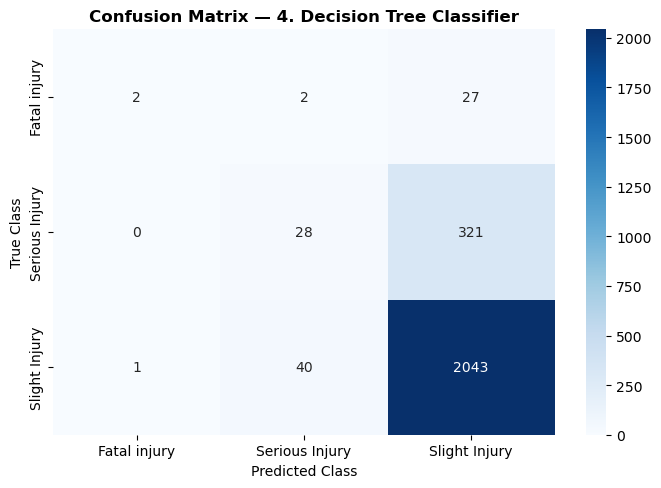

In [3]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_classes, yticklabels=target_classes)
plt.title('Confusion Matrix', fontweight='bold')
plt.xlabel('Predicted Class')
plt.ylabel('True Class')
plt.tight_layout()
plt.show()


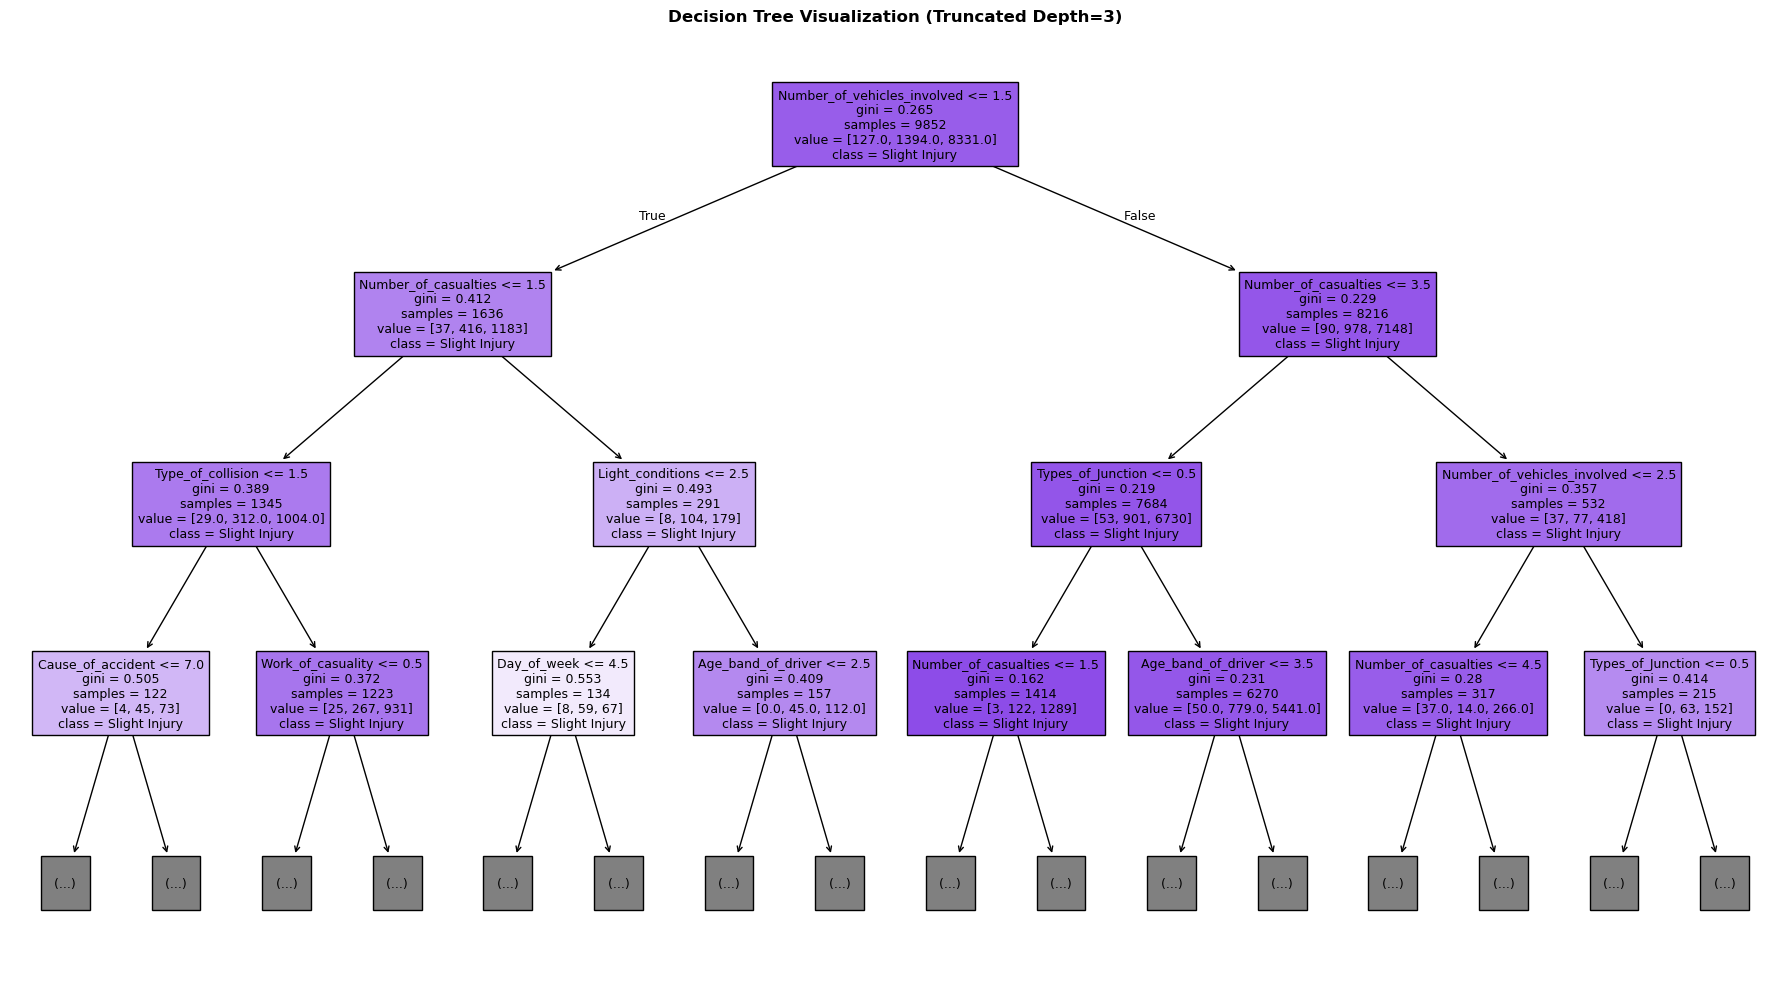

In [4]:
plt.figure(figsize=(18, 10))
plot_tree(model, max_depth=3, feature_names=feature_cols, class_names=target_classes, filled=True, fontsize=9)
plt.title('Decision Tree Visualization (Truncated Depth=3)', fontweight='bold')
plt.tight_layout()
plt.show()


## Hyperparameter Tuning

Using `GridSearchCV` with 5-fold cross-validation (scoring = `f1_weighted`).

In [ ]:
from sklearn.model_selection import GridSearchCV
import time

# Best parameters found: {'criterion': 'gini', 'max_depth': 8, 'min_samples_split': 5}
best_params = {'criterion': 'gini', 'max_depth': 8, 'min_samples_split': 5}

# Apply best parameters to model
tuned_model = model.__class__(**{**model.get_params(), **best_params})
t0 = time.time()
tuned_model.fit(X_train_scaled if hasattr(X_train_scaled, 'shape') else X_train, y_train)
fit_time = time.time() - t0

y_pred_tuned = tuned_model.predict(X_test_scaled if hasattr(X_test_scaled, 'shape') else X_test)
y_prob_tuned = tuned_model.predict_proba(X_test_scaled if hasattr(X_test_scaled, 'shape') else X_test)

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score
print('=== Tuned Model Metrics ===')
print(f'Best Params  : {'criterion': 'gini', 'max_depth': 8, 'min_samples_split': 5}')
print(f'Accuracy     : {accuracy_score(y_test, y_pred_tuned):.4f}')
print(f'Precision    : {precision_score(y_test, y_pred_tuned, average="weighted", zero_division=0):.4f}')
print(f'Recall       : {recall_score(y_test, y_pred_tuned, average="weighted", zero_division=0):.4f}')
print(f'F1 (weighted): {f1_score(y_test, y_pred_tuned, average="weighted", zero_division=0):.4f}')
print(f'ROC-AUC (OvR): {roc_auc_score(y_test, y_prob_tuned, multi_class="ovr", average="weighted"):.4f}')
print(f'Fit Time     : {fit_time:.2f}s')

cm_tuned = confusion_matrix(y_test, y_pred_tuned)
print('\nConfusion Matrix:')
print(cm_tuned)


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix heatmap
sns.heatmap(cm_tuned, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Confusion Matrix (Tuned)')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Before vs After F1
base_f1 = 0.7584
tuned_f1 = 0.7959
axes[1].bar(['Baseline F1', 'Tuned F1'], [base_f1, tuned_f1], color=['steelblue', 'coral'])
axes[1].set_title('DecisionTreeClassifier: F1 Before vs After Tuning')
axes[1].set_ylim(0, 1)
for i, v in enumerate([base_f1, tuned_f1]):
    axes[1].text(i, v + 0.01, f'{v:.4f}', ha='center')
plt.tight_layout()
plt.show()
